# 4.1 — Geometric (logit-linear) persona combination

**Pre-registration (written 2026-10-26, before any fit was run).** Spec: `persona_geom_mixture.md`, Experiment 1.

Question: does a per-token, logit-linear combination of the 87 base contexts (86 personas + generic header),
P_c(a_t) = softmax(Σ_s c_s z_s,t), reproduce Instruct's answers, where the fixed-weight *arithmetic* mixture missed by
0.82 nats/token (−1.723 vs Instruct's own −0.898)? Hold-out log P/token, fit on the training half of `data/basis_split.json`.

How each outcome will be read (from the spec; the error bar must clear a boundary before a row is chosen):

| Result | Reading |
|---|---|
| Fit A closes most of the 0.82 gap (gets near −0.95) | Post-training ≈ a new state inside the span of persona states; the arithmetic mixture used the wrong algebra. Strong support for a log-linear form of the persona selection model |
| Fit A reaches about the soft-prefix ceiling | The persona span is as good as any context; what remains is a change in dynamics, not a missing persona |
| Fit A barely beats the arithmetic mixture | Persona states don't span the needed direction, even though a soft prefix gets further. Look at which tokens carry the residual |
| Large negative c on some personas | Post-training "subtracts" a base character. Worth a dedicated follow-up |

Controls with expected outcomes: base-assistant answers, gap at or below the arithmetic mixture's 0.006 nats/token;
synthetic answers from c = (hhh 0.7, e14 0.6, fred −0.3), recovered c close to the truth and hold-out gap ≈ 0;
fit D (one persona, free scale) best scale ≈ 1 (the earlier tempering result).

Note added before running: the soft-prefix ceiling is being re-measured on this split (the old −1.37 came from a
different split; the old prefix gives −1.338 on this hold-out but is partly in-sample there).

My own prior (the agent's, for the record): fit A improves on the arithmetic mixture by a modest amount (0.05–0.2),
because the Instruct-specific tokens found in notebook 1.8 (em-dashes, house phrasing) are rare under every base persona,
and a product of personas can only reweight what the personas already predict.


## Setup

Everything below reads saved outputs; nothing is refitted here. Fits were run by `scripts/phase4_geom_fit.py` on stored final
hidden states (`$SCRATCH/persona_phase4/hidden/<run>/`, made by `scripts/phase4_hidden_states.py`); commands, git commits and
logs are in `NOTES.md` (2026-10-26 entry) and in each `config_<letters>.json`. Hold-out = the 150 test questions of
`data/basis_split.json`; ± = question-bootstrap standard error (300 resamples, seed 1, the same resamples for every row of
a run, so differences between rows have their own, smaller, error: column "± vs arithmetic").

In [1]:
import os, sys, json, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
REPO = Path.cwd().resolve().parent; os.chdir(REPO); sys.path.insert(0, str(REPO / "scripts"))
from phase1_basis_analysis import boot
E = REPO / "results/phase4/exp1"

def load_run(run):
    """Merge the fits_*.json of separate invocations of phase4_geom_fit.py for one run."""
    out = {"fits": {}, "holdout": {}}
    for f in sorted((E / run).glob("fits_*.json")):
        r = json.load(open(f)); out["fits"].update(r.get("fits", {})); out["holdout"].update(r.get("holdout", {}))
        for k in ["A_lambda_selection", "D_all_single", "E_greedy", "check_generic", "arithmetic", "n_fit", "n_test"]:
            if k in r: out[k] = r[k]
    return out

def table(run, extra=None):
    r = load_run(run); rows = []
    for k, v in r["holdout"].items():
        f = r["fits"].get(k, {})
        rows.append({"row": k, "hold-out log P/token": v["logp"], "±": v["se"], "± vs arithmetic": v["minus_arithmetic_se"],
                     "fit-half": f.get("fit_half_logp"), "sum c": f.get("sum_c")})
    for k, (x, se) in (extra or {}).items(): rows.append({"row": k, "hold-out log P/token": x, "±": se})
    return pd.DataFrame(rows).set_index("row").round(4)

def ref_rows(run, prefix=None):
    """Self-score and soft-prefix score on exactly the hold-out answers of the fits."""
    ha = np.load(sorted((E / run).glob("holdout_per_answer_*.npz"))[0]); rows, q = ha["rows"], ha["qidx"]; out = {}
    s = REPO / "results/phase4/self_tokens" / f"{run}.npz"
    if s.exists():
        s = np.load(s); lp, n = s["total"][rows], np.diff(s["offsets"])[rows]; sd, _ = boot([lp], [n], q); out["self-score (chat template)"] = (lp.sum() / n.sum(), sd[0])
    if prefix and Path(prefix).exists():
        p = np.load(prefix); lp, n = p["lp"][rows], p["n_tokens"][rows]; sd, _ = boot([lp], [n], q); out["base + soft prefix"] = (lp.sum() / n.sum(), sd[0])
    return out

## 1. Checks before any fit

* The stored hidden states reproduce the Phase 1 scores: the generic header as a one-hot c, recomputed from the hidden states,
  against the stored per-answer score.
* The reference numbers of the spec: generic header −1.758 and Instruct self −0.898 on this hold-out.

In [2]:
INST, BASE, SYN = "instruct_unknown_casual_v1", "base_unknown_casual_short_v1", "synthetic_run"
for run in [INST, BASE, SYN]:
    r = load_run(run); print(run, {k: round(v, 6) for k, v in r["check_generic"].items()}, "| fit", r["n_fit"], "hold-out", r["n_test"], "answers")
print("Instruct self on the hold-out:", {k: round(v[0], 4) for k, v in ref_rows(INST).items()})

instruct_unknown_casual_v1 {'holdout_from_hidden': -1.758366, 'holdout_stored': -1.758429, 'max_abs_diff_per_answer': 0.170038} | fit 1200 hold-out 1200 answers
base_unknown_casual_short_v1 {'holdout_from_hidden': -1.6119, 'holdout_stored': -1.611893, 'max_abs_diff_per_answer': 0.167091} | fit 1156 hold-out 1167 answers
synthetic_run {'holdout_from_hidden': -1.722131, 'holdout_stored': -1.722161, 'max_abs_diff_per_answer': 0.233867} | fit 295 hold-out 290 answers
Instruct self on the hold-out: {'self-score (chat template)': np.float64(-0.8985)}


## 2. Instruct answers: every fit

Fits (coefficients on the fit half, scores on the hold-out half): A free c (λ chosen on a validation split; both penalty
targets chose λ = 0, so A has a single row); B c ≥ 0; C c ≥ 0 and Σc = 1; D one persona with a free scale; E greedy
forward selection (12 steps). Reference rows: generic header, arithmetic mixture of the same 87 contexts, the soft prefix
retrained on this split, and Instruct's own score.

In [3]:
PREFIX = REPO / "results/phase4/exp1/prefix_instruct_L128/scores.npz"
refs = ref_rows(INST, PREFIX); T = table(INST, refs); display(T)
arith, self_ = T.loc["arithmetic mixture", "hold-out log P/token"], T.loc["self-score (chat template)", "hold-out log P/token"]
print("share of the arithmetic -> self distance closed:")
for k in T.index:
    if k not in ("self-score (chat template)",): print(f"  {k:28s} {100 * (T.loc[k, 'hold-out log P/token'] - arith) / (self_ - arith):6.1f}%")

,hold-out log P/token,±,± vs arithmetic,fit-half,sum c
row,,,,,
generic header,-1.7584,0.0115,0.0012,NaN,NaN
arithmetic mixture,-1.7225,0.0113,0.0000,NaN,NaN
A_free_lambda0,-1.6045,0.0121,0.0036,-1.5778,1.0423
C_pool,-1.7140,0.0112,0.0007,-1.6902,1.0000
B_nonneg,-1.7138,0.0113,0.0008,-1.6899,1.0154
D_single_scaled,-1.7307,0.0113,0.0009,-1.7070,0.9955
D persona at scale 1,-1.7307,0.0113,0.0009,NaN,NaN
E_greedy_final,-1.6450,0.0118,0.0028,-1.6220,1.0335
self-score (chat template),-0.8985,0.0091,NaN,NaN,NaN


share of the arithmetic -> self distance closed:
  generic header                 -4.4%
  arithmetic mixture              0.0%
  A_free_lambda0                 14.3%
  C_pool                          1.0%
  B_nonneg                        1.1%
  D_single_scaled                -1.0%
  D persona at scale 1           -1.0%
  E_greedy_final                  9.4%
  base + soft prefix             39.5%


In [4]:
r = load_run(INST)
print("lambda selection (validation log P/token):")
for tgt, d in r["A_lambda_selection"].items(): print(" ", tgt, [(g["lambda"], round(g["val_logp"], 4)) for g in d["grid"]], "-> chosen", d["chosen_lambda"])
for k, f in r["fits"].items():
    print(f"\n{k}: sum c {f['sum_c']:.3f}; top |c|:", ", ".join(f"{n} {v:+.2f}" for n, v in f["top_abs_c"][:10]))

lambda selection (validation log P/token):
  zero [(0.0, -1.57), (0.0001, -1.5702), (0.001, -1.5708), (0.01, -1.5913)] -> chosen 0.0
  generic [(0.0, -1.57), (0.0001, -1.5701), (0.001, -1.5709), (0.01, -1.5921)] -> chosen 0.0

A_free_lambda0: sum c 1.042; top |c|: hhh +1.70, e14 +1.03, e34 -1.02, neutral +0.89, e60 +0.80, e59 -0.68, e64 +0.54, fred +0.53, e51 -0.53, e53 -0.52

C_pool: sum c 1.000; top |c|: hhh +0.39, e14 +0.32, fred +0.29, e44 +0.00, neutral +0.00, formal +0.00, e04 +0.00, e13 +0.00, e49 +0.00, e76 +0.00

B_nonneg: sum c 1.015; top |c|: hhh +0.40, e14 +0.32, fred +0.30, evil +0.00, formal +0.00, neutral +0.00, e00 +0.00, sycophant +0.00, e02 +0.00, e03 +0.00

D_single_scaled: sum c 0.995; top |c|: e14 +1.00, hhh +0.00, evil +0.00, fred +0.00, formal +0.00, neutral +0.00, e00 +0.00, sycophant +0.00, e02 +0.00, e03 +0.00

E_greedy_final: sum c 1.033; top |c|: hhh +1.66, e14 +0.90, e34 -0.72, e59 -0.59, e39 -0.59, e27 +0.55, fred +0.55, e49 +0.49, e63 -0.42, e05 -0.37


### Greedy selection (E) and the single-persona fit (D)

In [5]:
r = load_run(INST)
cur = pd.DataFrame(r["E_greedy"]).set_index("k").round(4); display(cur)
d = pd.DataFrame(r["D_all_single"]).T.sort_values("fit_half_logp", ascending=False).round(4); display(d)

,added,c_added,fit_half_logp,holdout_logp
k,,,,
2,e14,0.9938,-1.7070,-1.7307
3,fred,0.3855,-1.6927,-1.7151
4,e18,-0.3244,-1.6821,-1.7043
5,e05,-0.2530,-1.6753,-1.6976
6,hhh,0.7311,-1.6632,-1.6850
7,e63,-0.9968,-1.6471,-1.6724
8,e27,0.4157,-1.6419,-1.6665
9,e39,-0.5159,-1.6374,-1.6604
10,e49,0.4001,-1.6336,-1.6558


,scale,fit_half_logp
e14,0.9955,-1.7070
hhh,1.0104,-1.7082
neutral,1.0088,-1.7113
e44,1.0046,-1.7260
e64,0.9995,-1.7271
e49,1.0029,-1.7272
e62,1.0125,-1.7281
e69,0.9952,-1.7293
e04,1.0119,-1.7313
e29,0.9846,-1.7318


## 3. Figure 1

-> results/phase4/fig1_geometric_fits.png



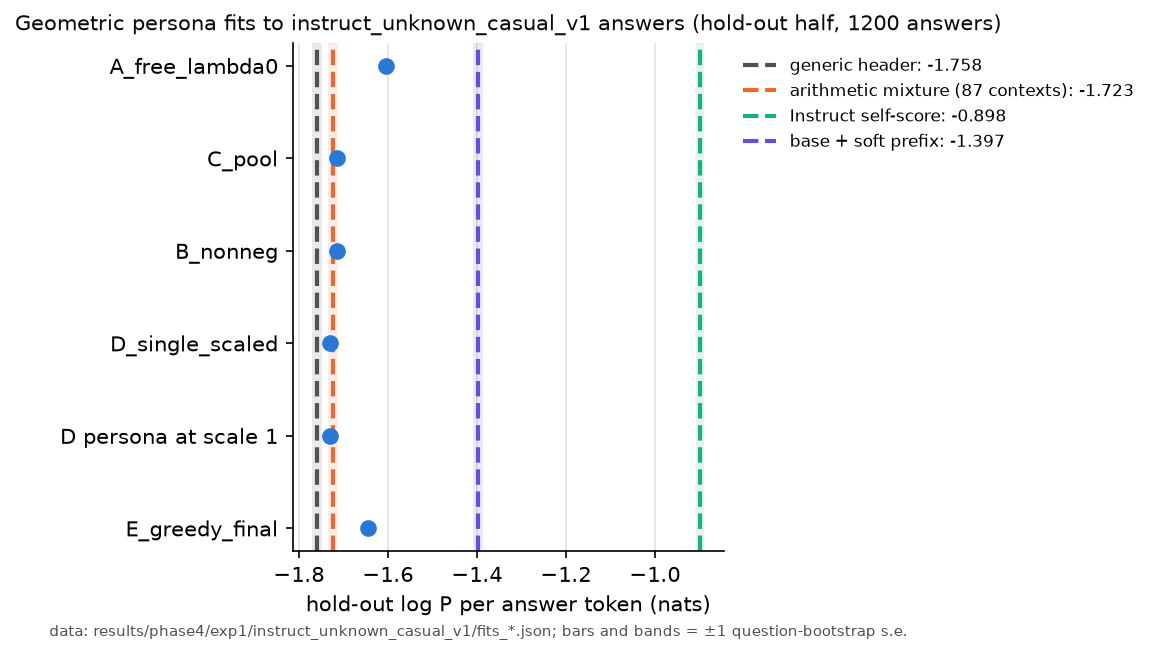

In [6]:
import subprocess
print(subprocess.run([sys.executable, "scripts/phase4_fig1.py", "--run", INST], capture_output=True, text=True).stdout)
display(Image("results/phase4/fig1_geometric_fits.png"))

## 4. Controls

**Synthetic calibration.** 600 answers (295 fit and 290 hold-out answers usable) sampled token by token from the known combination
c = (hhh 0.7, e14 0.6, fred −0.3) of base personas (`scripts/phase4_synthetic.py`). A perfect method recovers c and the
hold-out score of the true c (row `T_true_c`).

In [7]:
display(table(SYN))
r = load_run(SYN)
for k in ["A_free_lambda0", "A_free_l2zero_0.001", "E_greedy_final", "T_true_c"]:
    if k in r["fits"]: print(f"{k:22s}", ", ".join(f"{n} {v:+.2f}" for n, v in r["fits"][k]["top_abs_c"][:5]))
print("greedy order:", [(e["added"], round(e["c_added"], 2)) for e in r["E_greedy"][:4]])

,hold-out log P/token,±,± vs arithmetic,fit-half,sum c
row,,,,,
generic header,-1.7221,0.0325,0.0013,NaN,NaN
arithmetic mixture,-1.6971,0.0326,0.0000,NaN,NaN
T_true_c,-1.6871,0.0327,0.0009,-1.6818,1.0000
A_free_lambda0,-1.6881,0.0328,0.0013,-1.6777,0.9949
A_free_l2generic_0.0001,-1.6881,0.0328,0.0013,-1.6777,0.9948
C_pool,-1.6943,0.0326,0.0004,-1.6892,1.0000
B_nonneg,-1.6943,0.0326,0.0004,-1.6892,1.0029
D_single_scaled,-1.6990,0.0328,0.0007,-1.6963,1.0069
D persona at scale 1,-1.6992,0.0327,0.0007,NaN,NaN


A_free_lambda0         e14 +0.68, hhh +0.64, fred -0.31, e30 -0.21, e59 -0.19
E_greedy_final         e14 +0.73, hhh +0.59, fred -0.30, e00 -0.12, e54 +0.11
T_true_c               hhh +0.70, e14 +0.60, fred -0.30, evil +0.00, formal +0.00
greedy order: [('hhh', 0.86), ('e14', 0.57), ('fred', -0.35), ('e79', 0.07)]


**Base-assistant answers.** Sampled from the base model under the generic header, so the generic one-hot is the true
model; a fit should gain about nothing on the hold-out.

In [8]:
display(table(BASE))

,hold-out log P/token,±,± vs arithmetic,fit-half,sum c
row,,,,,
generic header,-1.6119,0.0116,0.0002,NaN,NaN
arithmetic mixture,-1.6117,0.0116,0.0000,NaN,NaN
A_free_lambda0,-1.6049,0.0117,0.0004,-1.5986,1.0753
A_free_l2generic_0.01,-1.6048,0.0118,0.0004,-1.5991,1.0738
C_pool,-1.6109,0.0116,0.0001,-1.6060,1.0000
B_nonneg,-1.6058,0.0117,0.0004,-1.6005,1.0717


## 5. Where the remaining gap sits (fit A vs Instruct's own score)

Per hold-out token, gap = log P_self − log P_fit (`scripts/phase4_residual.py`). The first answer token is dropped (the two
formats tokenise it differently) and only answers whose remaining token ids match are kept.

1147/1200 answers aligned, 51355 tokens


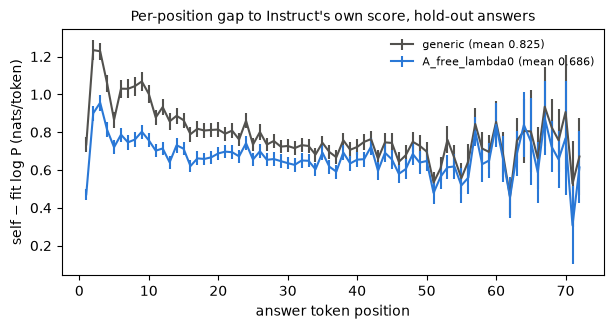

,token,count,mean_gap,share_of_total_gap
0,—,565,1.987,0.032
1,you,1695,0.533,0.026
2,it,2364,0.362,0.024
3,.,2074,0.379,0.022
4,the,1358,0.548,0.021
5,just,567,1.265,0.020
6,or,607,0.909,0.016
7,a,898,0.568,0.014
8,and,869,0.541,0.013
9,",",2260,0.189,0.012


In [9]:
R = json.load(open(E / INST / "residual_A_free_lambda0.json"))
print(f"{R['answers_aligned']}/{R['answers']} answers aligned, {R['tokens']} tokens")
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, col in [("generic", "#52514e"), ("A_free_lambda0", "#2a78d6")]:
    bp = pd.DataFrame(R[k]["by_position"]); ax.errorbar(bp["pos"], bp["mean_gap"], yerr=bp["se"], color=col, lw=1.5, label=f"{k} (mean {R[k]['mean_gap_per_token']:.3f})")
ax.set_xlabel("answer token position"); ax.set_ylabel("self − fit log P (nats/token)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Per-position gap to Instruct's own score, hold-out answers", fontsize=10); plt.show()
display(pd.DataFrame(R["A_free_lambda0"]["top_types"]).round(3))

## What we saw (2026-10-27)

**Bottom line: a geometric (logit-linear) combination of the 87 base contexts does better than the arithmetic mixture, but
it closes only about 14% of the distance to Instruct. The soft prefix gets about three times further. The pre-registered
reading is the third row: the persona states do not span what post-training added, even though some context (the prefix)
gets further.**

Hold-out log P per token on the 1,200 Instruct answers of the 150 test questions (± question bootstrap; differences from the
arithmetic mixture have their own, smaller, paired errors):

| row | log P/token | vs arithmetic |
|---|---|---|
| generic header | −1.758 ± 0.012 | −0.036 |
| arithmetic mixture (87 contexts) | −1.723 ± 0.011 | 0 |
| D one persona (e14), free scale 0.995 | −1.731 ± 0.011 | −0.008 ± 0.001 |
| C c ≥ 0, Σc = 1 (hhh 0.39, e14 0.32, fred 0.29) | −1.714 ± 0.011 | +0.009 ± 0.001 |
| B c ≥ 0 (the same three personas) | −1.714 ± 0.011 | +0.009 ± 0.001 |
| E greedy, 12 contexts | −1.645 ± 0.012 | +0.078 ± 0.003 |
| **A free c, λ = 0 (chosen on validation)** | **−1.605 ± 0.012** | **+0.118 ± 0.004** |
| base + soft prefix (retrained on this split) | −1.397 | +0.33 |
| Instruct self-score | −0.898 | +0.82 |

* **Gain:** fit A is 0.118 ± 0.004 nats/token better than the arithmetic mixture, at the low end of my prior (0.05–0.2).
  Measured from the arithmetic mixture, that is 14% of the distance to Instruct; the prefix covers 39%. Fit A is not near
  −0.95 (row 1) and not near the prefix (row 2).
* **Without negative weights there is no gain.** With c ≥ 0 (B), or a weighted geometric mean of personas (C), the fit
  picks hhh, e14 and fred and gains only 0.009. Every bit of fit A's advantage needs negative coefficients.
* **Large negative coefficients (row 4), but they are not one character being subtracted.** Fit A has 23 coefficients
  above 0.3 in size; the positive ones sum to +11.1 and the negative ones to −10.1, so their sum is about 1. The biggest are
  hhh +1.70, e14 +1.03, e34 −1.02, neutral +0.89, e60 +0.80 and e59 −0.68. The greedy fit agrees on the main ones (hhh, e14,
  fred positive; e34, e59, e39, e63 negative). Read as a whole, the fit sharpens the logits along *differences* between
  personas rather than removing any one of them. The individual values should not be over-read: the regularisation grid was
  flat (validation changed by less than 0.001 up to λ = 1e-3), so many coefficient vectors score about the same.
* **Tempering does nothing (D).** The best scale of each of the 10 best single personas is 0.985–1.012, as found earlier.
* **Overfitting is small:** fit half −1.578 vs hold-out −1.605. The validation-chosen λ was 0 for both penalty targets.

**Where the remaining 0.69 nats/token sits.** It is spread over ordinary tokens: per-position plot above, top types in the
table. The em-dash, Instruct's most distinctive token, is still the largest single type (2.0 nats per occurrence under fit A,
down from 5.0 under the generic header), but it carries only 3% of the remaining gap. Function words (" you", " it", ".",
" the", " just", " or") each carry 1.5–2.6%. No small set of tokens explains it.

**Controls pass.**
* Synthetic answers sampled from a known combination (hhh 0.7, e14 0.6, fred −0.3): fit A recovers 0.64, 0.68, −0.31 and lands
  0.001 below the true-c score; greedy picks exactly those three first and then adds nothing. The method finds a geometric
  combination of these personas when one is there. The synthetic signal is modest (true c is 0.035 above the generic header),
  so this tests the optimizer, not large departures.
* Base-assistant answers (sampled under the generic header): fit A gains 0.007 ± 0.0004 over the generic header, with c
  staying near one-hot generic (0.99). The fit does not invent gains.

**What went wrong on the way (kept for the record).** The first objective computed logits in bf16 (the model's own convention).
That made the objective step-like at the 1e-5–1e-4 level and stopped L-BFGS early (a restart from another point stalled
0.056 short). All fits were redone with fp32 logits (TF32 on an exact split, within 1.4e-7 of full fp32). The headline fit A
barely moved (−1.606 → −1.605), but the synthetic recovery and the greedy fit did. The superseded outputs are in
`results/phase4/exp1/<run>/superseded_bf16_objective/`. With fp32 logits the generic one-hot no longer reproduces the stored
scores exactly (the model's own logits are bf16-rounded): −1.75837 vs −1.75843 on the hold-out.

**Caveats.** One question split (the basis split) and one seed. The comparison with the prefix uses a prefix trained with
gradient descent on all 128 × 4096 numbers, while fit A has 87 coefficients. The 87 contexts are the ones written or
elicited in Phase 1; a different basis could span more, which is what Experiment 2 asks with 499 contexts at the
sequence level.
